In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')


for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].astype('category').cat.codes

X = df.drop('NObeyesdad', axis=1).values
y = df['NObeyesdad'].astype('category').cat.codes.values  


X = (X - X.mean(axis=0)) / X.std(axis=0)


np.random.seed(42)
indices = np.random.permutation(len(X))
train_size = int(0.8 * len(X))
train_idx, test_idx = indices[:train_size], indices[train_size:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]


def linear_regression(X, y):
    ones = np.ones((X.shape[0], 1))
    X_b = np.hstack([ones, X])
    weights = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y
    return weights

def predict_linear(X, weights):
    X_b = np.hstack([np.ones((X.shape[0], 1)), X])
    return X_b @ weights

weights_lin = linear_regression(X_train, y_train)
y_pred_lin = predict_linear(X_test, weights_lin)
mse_lin = np.mean(( y_test - y_pred_lin)**2)

In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def logistic_regression(X, y, lr=0.01, epochs=1000):
    X_b = np.hstack([np.ones((X.shape[0], 1)), X])
    weights = np.zeros(X_b.shape[1])
    for _ in range(epochs):
        z = X_b @ weights
        predictions = sigmoid(z)
        gradient = X_b.T @ (predictions - y) / y.size
        weights -= lr * gradient
    return weights


mask = y_train < 2
X_train_bin = X_train[mask]
y_train_bin = y_train[mask]
X_test_bin = X_test[y_test < 2]
y_test_bin = y_test[y_test < 2]

weights_log = logistic_regression(X_train_bin, y_train_bin)
pred_log = sigmoid(np.hstack([np.ones((X_test_bin.shape[0], 1)), X_test_bin]) @ weights_log) > 0.5
acc_log = np.mean(pred_log == y_test_bin)

In [ ]:
def naive_bayes_train(X, y):
    classes = np.unique(y)
    mean = {}
    var = {}
    prior = {}
    for c in classes:
        X_c = X[y == c]
        mean[c] = X_c.mean(axis=0)
        var[c] = X_c.var(axis=0) + 1e-6  # avoid zero variance
        prior[c] = X_c.shape[0] / X.shape[0]
    return mean, var, prior

def naive_bayes_predict(X, mean, var, prior):
    results = []
    for x in X:
        posteriors = []
        for c in mean:
            likelihood = -0.5 * np.sum(np.log(2 * np.pi * var[c]))
            likelihood -= 0.5 * np.sum(((x - mean[c])**2) / var[c])
            posterior = likelihood + np.log(prior[c])
            posteriors.append(posterior)
        results.append(np.argmax(posteriors))
    return np.array(results)

mean_nb, var_nb, prior_nb = naive_bayes_train(X_train, y_train)
pred_nb = naive_bayes_predict(X_test, mean_nb, var_nb, prior_nb)
acc_nb = np.mean(pred_nb == y_test)

In [ ]:
def knn_predict(X_train, y_train, X_test, k=5):
    predictions = []
    for x in X_test:
        distances = np.sqrt(np.sum((X_train - x)**2, axis=1))
        k_indices = np.argsort(distances)[:k]
        k_nearest_labels = y_train[k_indices]
        values, counts = np.unique(k_nearest_labels, return_counts=True)
        predictions.append(values[np.argmax(counts)])
    return np.array(predictions)

pred_knn = knn_predict(X_train, y_train, X_test, k=5)
acc_knn = np.mean(pred_knn == y_test)


Model Comparison:
Linear Regression MSE: 2.6868
Binary Logistic Regression Accuracy: 59.60%
Naive Bayes Accuracy: 63.12%
KNN Accuracy: 85.11%


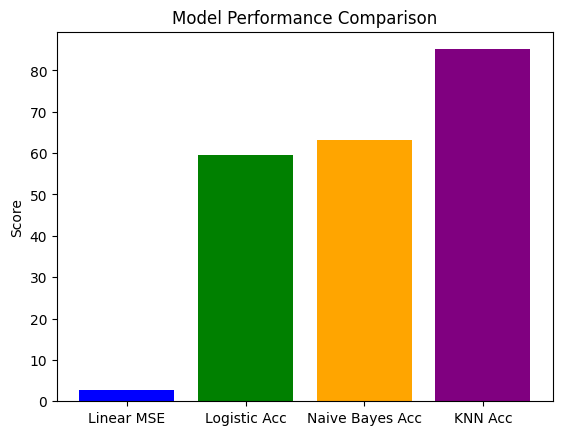

In [5]:
print("\nModel Comparison:")
print(f"Linear Regression MSE: {mse_lin:.4f}")
print(f"Binary Logistic Regression Accuracy: {acc_log*100:.2f}%")
print(f"Naive Bayes Accuracy: {acc_nb*100:.2f}%")
print(f"KNN Accuracy: {acc_knn*100:.2f}%")


plt.bar(['Linear MSE', 'Logistic Acc', 'Naive Bayes Acc', 'KNN Acc'],
        [mse_lin, acc_log*100, acc_nb*100, acc_knn*100],
        color=['blue', 'green', 'orange', 'purple'])
plt.ylabel('Score')
plt.title('Model Performance Comparison')
plt.show()